# 03 Match context EDA

**Objective.** Describe scoring by phase, format and era so the baseline knows what context it has to absorb.

**Inputs.** data_prep/output tables and balls_clean.parquet.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from common import style
from common.io import read_parquet, read_table
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

## Step 1. Scoring by phase and competition type

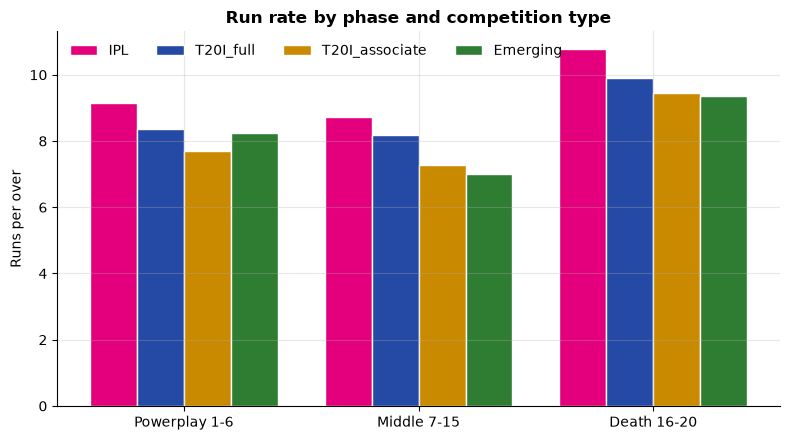

,comp_type,phase,runs_per_over,legal,wkts,balls_per_wkt
0,Emerging,DEATH,9.365451,1453,128,11.351562
1,Emerging,MID,7.016393,3111,156,19.942308
2,Emerging,PP,8.243043,2156,106,20.339623
3,IPL,DEATH,10.773711,18441,1532,12.037206
4,IPL,MID,8.720004,38047,1756,21.666856
5,IPL,PP,9.147940,25632,1074,23.865922
6,T20I_associate,DEATH,9.437784,2419,226,10.703540
7,T20I_associate,MID,7.261029,5191,280,18.539286
8,T20I_associate,PP,7.690894,3591,169,21.248521
9,T20I_full,DEATH,9.917273,18688,1672,11.177033


In [2]:
from data_prep import plots as p1, audit
balls = read_parquet("data_prep", "balls_clean.parquet")
p1.scoring_by_phase(); plt.show()
read_table("data_prep", "scoring_by_phase.csv")

## Step 2. Impact Player era inflation in the IPL

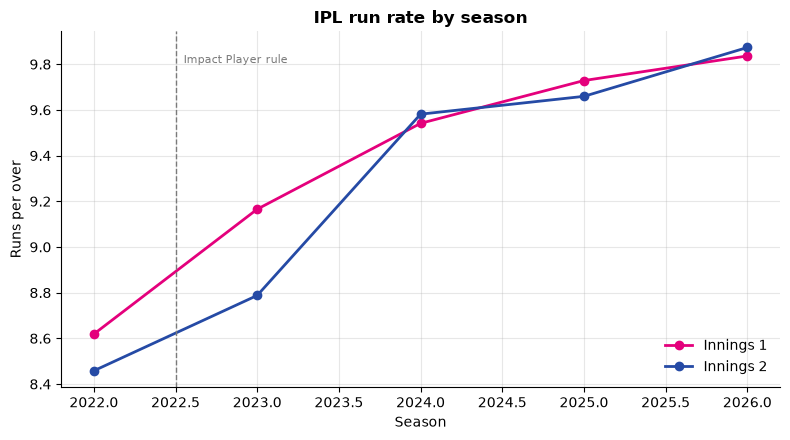

,season,innings,runs,legal,run_rate
0,2022,1,12661,8814,8.618788
1,2022,2,11730,8321,8.458118
2,2023,1,12992,8505,9.165432
3,2023,2,11849,8090,8.787886
4,2024,1,13461,8465,9.541170
5,2024,2,12510,7834,9.581312
6,2025,1,13268,8183,9.728461
7,2025,2,12277,7626,9.659323
8,2026,1,13900,8479,9.836066
9,2026,2,12840,7803,9.873126


In [3]:
p1.impact_era(); plt.show()
read_table("data_prep", "impact_era.csv")

## Step 3. Venue scoring index, venues with five or more first innings

In [4]:
audit.venue_index(balls).head(10)

,venue_id,mean,count
0,70,221.166667,6
1,101,205.285714,7
2,48,204.700000,10
3,10,202.071429,28
4,67,196.200000,5
5,94,195.750000,8
6,6,194.523810,21
7,79,194.000000,6
8,2,193.840000,25
9,7,193.451613,31


## Step 4. Innings total distribution

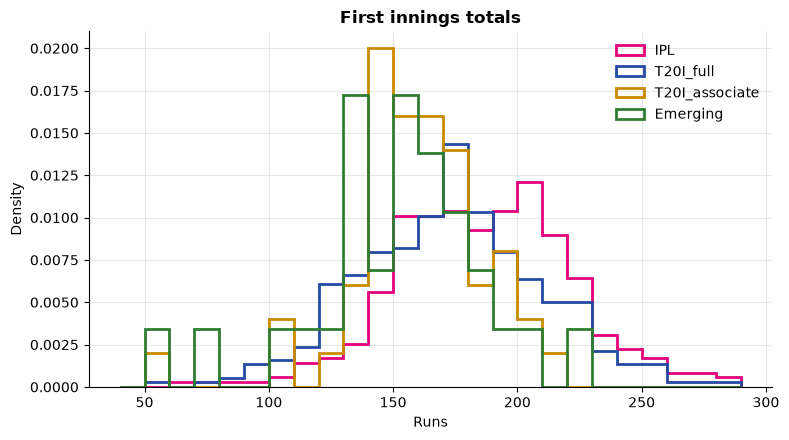

In [5]:
p1.innings_totals(balls); plt.show()

## Step 5. Chase success by target

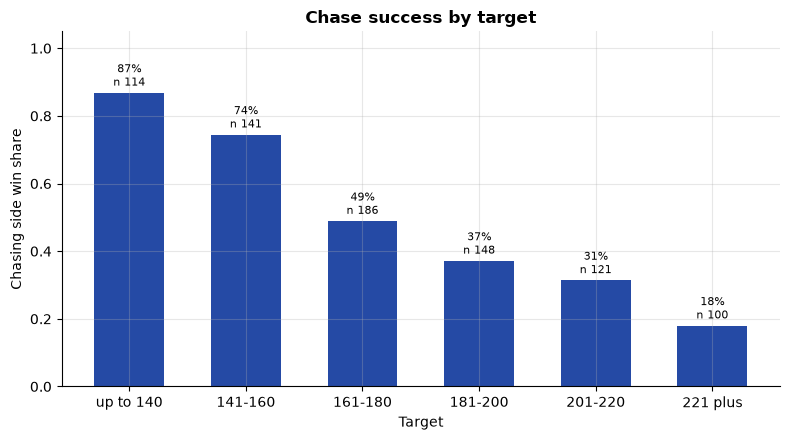

In [6]:
p1.chase_success(); plt.show()

## Step 6. Balls by batting slot and phase

In [7]:
audit.slot_balls(balls)

phase,batting_order,DEATH,MID,PP
0,1,1170,9717,20867
1,2,1600,11246,19246
2,3,2513,15091,11378
3,4,4580,18229,5183
4,5,6348,14348,1755
5,6,7217,9312,403
6,7,6758,5298,68
7,8,4945,2071,8
8,9,3190,982,0
9,10,2011,389,0


## Step 7. Pace and spin usage by phase

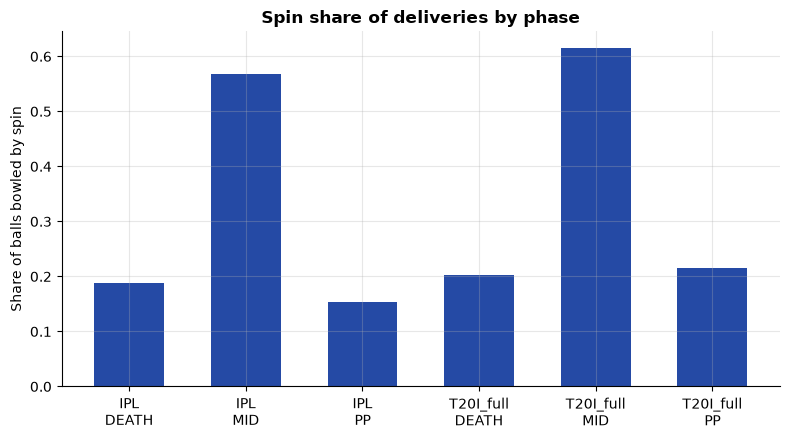

In [8]:
p1.pace_spin(); plt.show()

## Key findings

In [9]:
s = read_table("data_prep", "scoring_by_phase.csv").set_index(["comp_type", "phase"])["runs_per_over"]
ie = read_table("data_prep", "impact_era.csv").groupby("season")["run_rate"].mean()
cs = read_table("data_prep", "chase_success.csv").set_index("band")["chase_win"]
display(Markdown(f'''
- IPL death overs run at {s[("IPL", "DEATH")]:.1f} an over against {s[("T20I_full", "DEATH")]:.1f} in full-member T20Is.
- IPL run rate went from {ie.loc[2022]:.2f} in 2022 to {ie.loc[ie.index.max()]:.2f} in {ie.index.max()}, so era must be in the baseline.
- Chases of 140 or less succeed {cs.iloc[0]:.0%} of the time, chases of 221 plus only {cs.iloc[-1]:.0%}.
'''))


- IPL death overs run at 10.8 an over against 9.9 in full-member T20Is.
- IPL run rate went from 8.54 in 2022 to 9.85 in 2026, so era must be in the baseline.
- Chases of 140 or less succeed 87% of the time, chases of 221 plus only 18%.


## Outputs written

Figures 03_scoring_by_phase.png, 03_impact_era.png, 03_innings_totals.png, 03_chase_success.png, 03_pace_spin.png in data_prep/output/figures.